### Task 1: Dataset Generation & Preprocessing

In [1]:
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler

# 1. Generate synthetic datasets
# Dataset A: Isotropic/Spherical blobs
X_a, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=42)

# Dataset B: Non-spherical moon shapes
X_b, _ = make_moons(n_samples=300, noise=0.05, random_state=42)

# 2. Normalize features using StandardScaler
scaler = StandardScaler()
X_a_scaled = scaler.fit_transform(X_a)
X_b_scaled = scaler.fit_transform(X_b)

### Task 2: K-Means Clustering

#### Part 1: Apply K-Means on Dataset A

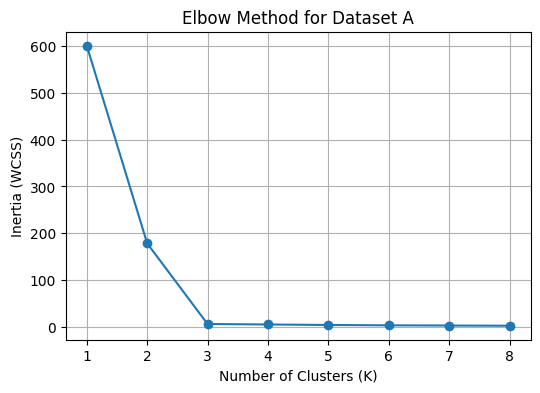

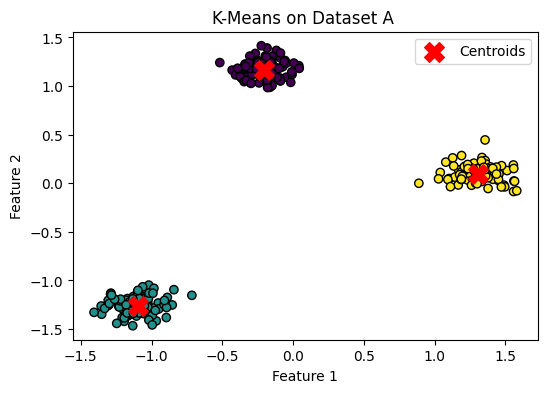

In [6]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


# 1. Elbow Method to find optimal K (K in [1, 8])
inertia_values = []
k_range = range(1, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_a_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot Inertia vs. K
plt.figure(figsize=(6, 4))
plt.plot(k_range, inertia_values, marker='o')
plt.title("Elbow Method for Dataset A")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.grid(True)
plt.show()

# 2. Fit K-Means with chosen K (K=3 based on elbow plot)
optimal_k = 3
kmeans_a = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
labels_a = kmeans_a.fit_predict(X_a_scaled)
centroids_a = kmeans_a.cluster_centers_

# 3. Plot clusters with centroids
plt.figure(figsize=(6, 4))
plt.scatter(X_a_scaled[:, 0], X_a_scaled[:, 1], c=labels_a, cmap='viridis', edgecolors='k')
plt.scatter(centroids_a[:, 0], centroids_a[:, 1], c='red', s=200, marker='X', label='Centroids')
plt.title("K-Means on Dataset A ")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

#### Part 2: Apply K-Means on Dataset B

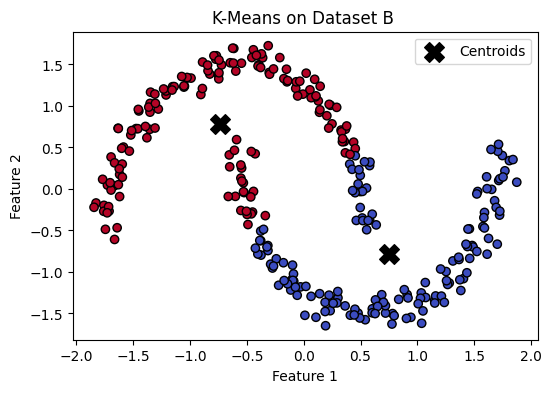

In [10]:
# Fit K-Means on Dataset B
kmeans_b = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_b = kmeans_b.fit_predict(X_b_scaled)
centroids_b = kmeans_b.cluster_centers_

# Plot clusters with centroids
plt.figure(figsize=(6, 4))
plt.scatter(X_b_scaled[:, 0], X_b_scaled[:, 1], c=labels_b, cmap='coolwarm', edgecolors='k')
plt.scatter(centroids_b[:, 0], centroids_b[:, 1], c='black', s=200, marker='X', label='Centroids')
plt.title("K-Means on Dataset B ")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

### Observation on Task 2

1. Why K=3 was chosen for Dataset A:
* In Dataset A, the Elbow Method showed a sharp drop in Inertia from K=1 to K=3, followed by a very flat line after K=3. The "elbow" bend appears distinctly at K=3, matching the 3 spherical clusters created in Task 1.

2. Why K=2 was used for Dataset B:
* Dataset B (make_moons) naturally consists of two intertwined crescent/moon shapes. Therefore, K=2 was selected to test if K-Means could separate these two visual groups.

3. K-Means fails on Dataset B:
* Spherical Assumption: K-Means assumes that all clusters are spherical (round) and convex.
* Distance-Based Boundaries: The algorithm partitions data using straight, linear boundaries based on Euclidean distance to cluster centroids.
* Result: Because the two moons are curved and wrapped around each other, a straight line cannot separate them. Instead of following the curves, K-Means simply cuts both moons in half, assigning parts of both shapes to each cluster.